# 07 · Groei, voederopname en voederconversie onderzoeken

<div style="text-align:justify;box-sizing:border-box;max-width:100%;overflow-wrap:anywhere;">

Op het bedrijf zijn gewichten en voederopnames door afzonderlijke toestellen geregistreerd. Je hebt ze via MQTT verzameld en via een API naar de kantoorcomputer gebracht. Nu gebruik je beide bronnen samen om te onderzoeken hoe de biggen in de verschillende hokken groeien en hoeveel voeder daarvoor nodig is.

Je begint met één dier en één afgebakende periode. Daarna maak je voor ieder hok grafieken van gewicht, gemiddelde groei, voederopname en voederconversie. Je beoordeelt daarbij steeds hoeveel dieren in de berekening konden worden meegenomen. Aan het einde bewaar je deze beginsituatie, zodat je later kunt zien wat een aanvulling met nieuwe gegevens verandert.

**Nodig:** dezelfde Codespace, je eigen branch, een geslaagde notebook 06 en `gegevens/werk/analyse_06.db`. Je gebruikt beide datasets, ongeacht je oorspronkelijke rol. De API hoeft voor deze oefening niet bereikbaar te zijn. De benodigde gegevens staan al in je analysedatabase.

Voer de cellen in volgorde uit. Bij twee facultatieve verkenningen kun je zelf een extra vergelijking maken. De basisberekening blijft beschikbaar als vast vergelijkingspunt.

</div>

## 1. De analysedatabase en de vorige controle ophalen

<div style="text-align:justify;box-sizing:border-box;max-width:100%;overflow-wrap:anywhere;">

**Uitvoeren:** in Codespaces (Notebook 07)

De gegevens staan op de computer die je voor de analyse gebruikt. In deze oefening is dat Codespaces. Je leest het analysebestand uitsluitend. Daardoor blijven je meetgegevens behouden terwijl je verschillende berekeningen en figuren maakt.

De eerste cel vergelijkt de inhoud met het automatische controlebestand van notebook 06. Ze laadt de velden die nodig zijn voor de analyse. In de figuren gebruik je hoknummers om de groepen te vergelijken.

</div>

In [1]:
_DOCENT_BRANCH_OVERRIDE = "student/proefdocent"

In [2]:
from pathlib import Path
from datetime import datetime, timezone
import json
import re
import subprocess
import sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

r = subprocess.run(["git", "rev-parse", "--show-toplevel"], capture_output=True, text=True)
if r.returncode:
    raise RuntimeError("Open notebook 07 vanuit de practicumrepository.")
hoofdmap = Path(r.stdout.strip())
branch = subprocess.check_output(["git", "branch", "--show-current"], cwd=hoofdmap, text=True).strip()
if not re.fullmatch(r"student/[a-z0-9][a-z0-9_-]*", branch) and "_DOCENT_BRANCH_OVERRIDE" in globals():
    branch = _DOCENT_BRANCH_OVERRIDE
instellingen = json.loads((hoofdmap / "gegevens/inlevering/01_werkplekcontrole.json").read_text(encoding="utf-8"))
deelnemer, rol = instellingen["deelnemerscode"], instellingen["rol"]
if branch != "student/" + deelnemer or instellingen.get("branch") != branch or rol not in ("gewichten", "voederopname"):
    raise ValueError("Controleer je eigen branch en instellingen uit notebook 01.")
controle06 = json.loads((hoofdmap / "gegevens/inlevering/06_apicontrole.json").read_text(encoding="utf-8"))
if controle06.get("deelnemerscode") != deelnemer or controle06.get("branch") != branch or not controle06.get("inhoud_gelijk_aan_05"):
    raise ValueError("Rond notebook 06 en de automatische inlevering af.")
sys.path.insert(0, str(hoofdmap / "programmatuur"))
from analyse_07 import (lees_analyse, selecteer, daggewichten, schat_gewicht,
                       bereken_intervallen, vat_hokken_samen, bewaar_basis, METHODE, STANDAARD_GRENZEN)
from figuren_07 import gewichtsfiguur, intervalfiguur, hokvolgorde
analysepad = hoofdmap / "gegevens/werk/analyse_06.db"
data, bronmanifest = lees_analyse(analysepad)
assert bronmanifest == controle06["herhaalde_import"]["bronnen"], "De database is veranderd sinds je controle uit 06."
print("Deelnemer:", deelnemer, "| Rol:", rol)
print("Gecontroleerde bronrecords:", len(data))
display(data.groupby(["bron", "meettype", "eenheid"]).size().rename("records").reset_index())

Deelnemer: proefdocent | Rol: gewichten
Gecontroleerde bronrecords: 226677


,bron,meettype,eenheid,records
0,asserva,gewichten,kg,80028
1,schauer,voederopname,g,146649


<div style="background-color:#e8f5e9;color:#1b5e20;border-left:5px solid #2e7d32;padding:14px;margin:12px 0;border-radius:4px;text-align:justify;box-sizing:border-box;max-width:100%;overflow-wrap:anywhere;white-space:normal;"><strong>Controle</strong><br>Je verwacht 80.028 gewichtsrecords in kg en 146.649 voederopnamerecords in g. Dit zijn aantallen bronrecords. Ze vertellen nog niet hoeveel dieren en perioden geschikt zijn voor een berekening.</div>

## 2. Van bezoekregistratie naar een vergelijking tussen dieren

<div style="text-align:justify;box-sizing:border-box;max-width:100%;overflow-wrap:anywhere;">

Een voederrecord bevat de opname tijdens één bezoek. Om de totale opname in een periode te kennen, tel je die bezoekwaarden op. Een gewichtsrecord beschrijft het lichaamsgewicht op een tijdstip. Gewichten tel je dus niet op over bezoeken. Voor groei vergelijk je een begin- en eindgewicht.

Je koppelt de bronnen met de dieridentificatie. Het hoknummer geeft aan bij welke groep het dier hoort. Een dier moet in beide bronnen aan hetzelfde, stabiele hok gekoppeld zijn. Een onbekende identificatie of een fout geregistreerd hok mag niet ongemerkt bij de groep worden geteld.

Bekijk eerst de kwaliteitscodes en de herkomst van de records. Deze informatie is behouden tijdens de overdracht. Een geïmputeerd gewicht is een eerder geschatte waarde. Een nulwaarde bij voeder kan een geregistreerd bezoek zonder opname zijn.

</div>

In [3]:
display(data.groupby(["bron", "foutcode", "vlag"], dropna=False).size().rename("records").reset_index())
display(data[data["bron"] == "asserva"].groupby("herkomst", dropna=False).size().rename("gewichtsrecords").reset_index())
print("Geregistreerde nulbezoeken in de voederbron:", int(((data["bron"] == "schauer") & (data["waarde"] == 0)).sum()))

,bron,foutcode,vlag,records
0,asserva,invalid PEN,errored,7
1,asserva,no error,0,71115
2,asserva,no error,flagged,8906
3,schauer,no error,0,74690
4,schauer,no error,flagged,71879
5,schauer,non-pig EID,errored,80


,herkomst,gewichtsrecords
0,0,78614
1,allocation,101
2,exit,2
3,imputed,1112
4,manualweighing,199


Geregistreerde nulbezoeken in de voederbron: 58924


<div style="text-align:justify;box-sizing:border-box;max-width:100%;overflow-wrap:anywhere;">

**Vraag 1.** Waarom is een voederrecord met waarde nul niet hetzelfde als een ontbrekende voederdag?

</div>

<div style="text-align:justify;box-sizing:border-box;max-width:100%;overflow-wrap:anywhere;">

**Jouw antwoord (Vraag 1):**

*Voeg hier je antwoord in. Tip: vergelijk een waargenomen bezoek met een periode zonder registratie.*

</div>

<div style="text-align:justify;box-sizing:border-box;max-width:100%;overflow-wrap:anywhere;">

**Antwoord 1**

Een nulbezoek is een opgeslagen waarneming: bij dat bezoek is geen opname geregistreerd. Bij een dag zonder records weten we niet of het dier niet at, de herkenning mislukte of de registratie uitviel. Een ontbrekende dag krijgt daarom niet automatisch nul gram.

</div>

## 3. De populatie, periode en kwaliteitsregels vastleggen

<div style="text-align:justify;box-sizing:border-box;max-width:100%;overflow-wrap:anywhere;">

**Uitvoeren:** in Codespaces (Notebook 07)

Een uitkomst hangt af van de gekozen dieren, periode en kwaliteitsregels. Je legt die daarom vóór de berekening vast. De regels hieronder vormen een transparante, verkennende lesmethode. Ze reconstrueren niet alle bewerkingen uit de oorspronkelijke gegevensverwerking.

Je verwijdert in de analyse records die expliciet als fout zijn aangeduid. Je gebruikt alleen dieren met een stabiele, overeenkomende hokcode in beide bronnen. Voor gewichten gebruik je oorspronkelijke toestelmetingen, handmatige wegingen en de startweging. Eerder geïmputeerde gewichten en uitstroomregistraties worden apart gehouden. Alle oorspronkelijke records blijven in de database staan.

Een record met `flagged` is een aandachtspunt. In de basisberekening blijft het behouden. De dagelijkse gewichtsmediaan vermindert de invloed van losse uitschieters, maar garandeert niet dat alle fouten verdwijnen. Ook de voederwaarden blijven inhoudelijk te beoordelen. Deze keuze voorkomt dat je zonder uitleg alle kleine en nulbezoeken verwijdert.

</div>

In [4]:
basis_vanaf = "2023-08-24"
basis_tot = "2023-09-21"  # Exclusieve bovengrens van de aangeleverde basisdata.
gewichten, voeder, populatie, selectiecontrole, koppeling_uitgesloten = selecteer(
    data, vanaf=basis_vanaf, tot=basis_tot, streng=False
)
display(selectiecontrole)
display(populatie.groupby("hok").size().rename("dieren").reindex(hokvolgorde(populatie["hok"])).reset_index())
print("Gekoppelde dieren:", len(populatie))
print("Dieren met onzekere koppeling:", len(koppeling_uitgesloten))
assert set(populatie["hok"]) == {str(i) for i in range(1, 11)}

,stap,bron,over,uitgesloten
0,Gekozen bronperiode,asserva,80028,0
1,Gekozen bronperiode,schauer,146649,0
2,Geldige herkenning,asserva,80021,7
3,Geldige herkenning,schauer,146569,80
4,Stabiel gekoppelde dieren,asserva,80021,0
5,Stabiel gekoppelde dieren,schauer,146569,0
6,Geldige tijd en waarde,asserva,80021,0
7,Geldige tijd en waarde,schauer,146569,0
8,Oorspronkelijke gewichten,asserva,78907,1114
9,Oorspronkelijke gewichten,schauer,146569,0


,hok,dieren
0,1,11
1,2,10
2,3,10
3,4,10
4,5,10
5,6,10
6,7,10
7,8,10
8,9,10
9,10,10


Gekoppelde dieren: 101
Dieren met onzekere koppeling: 0


<div style="text-align:justify;box-sizing:border-box;max-width:100%;overflow-wrap:anywhere;">

De basisbestanden bevatten 28 kalenderdagen, maar de eerste dag begint rond de middag. Bovendien heb je gewichten aan beide kanten van een tijdsgrens nodig om daar een gewicht te schatten. Daarom bereken je de hoofdresultaten vanaf **25 augustus om 00:00 tot 20 september om 00:00**. De resterende metingen op 20 september kunnen het eindgewicht ondersteunen. Je gebruikt geen latere meetdagen.

Je verdeelt deze periode in drie intervallen van zeven dagen en één interval van vijf dagen. Groei en voederopname worden omgerekend naar gram per dier per dag, zodat de verschillende intervallengtes herkenbaar en vergelijkbaar zijn.

</div>

In [5]:
grenzen = STANDAARD_GRENZEN.copy()
max_uren = 48
regels = {
    "basis_vanaf": basis_vanaf, "basis_tot_exclusief": basis_tot,
    "grenzen": grenzen, "max_afstand_dagmedianen_uren": max_uren,
    "flagged": "behouden", "imputed_en_exit": "uitgesloten",
    "voedertoewijzing": "bezoekstart, begin inclusief, einde exclusief",
    "dekking": "minstens één geldig voederrecord per dier per kalenderdag",
    "groei": "uitsluitend positieve groei voor voederconversie",
}
display(pd.DataFrame({"vanaf": grenzen[:-1], "tot_exclusief": grenzen[1:],
                      "dagen": np.diff(pd.to_datetime(grenzen)).astype("timedelta64[D]").astype(int)}))

,vanaf,tot_exclusief,dagen
0,2023-08-25,2023-09-01,7
1,2023-09-01,2023-09-08,7
2,2023-09-08,2023-09-15,7
3,2023-09-15,2023-09-20,5


<div style="background-color:#e8f5e9;color:#1b5e20;border-left:5px solid #2e7d32;padding:14px;margin:12px 0;border-radius:4px;text-align:justify;box-sizing:border-box;max-width:100%;overflow-wrap:anywhere;white-space:normal;"><strong>Interpretatie</strong><br>Een interval zonder positieve groei krijgt geen bruikbare voederconversie. Die dieren verdwijnen niet uit de controle: hun reden blijft zichtbaar. Door die keuze kunnen groepsresultaten gunstiger lijken dan de toestand van alle dieren samen. Vergelijk daarom altijd de uitkomst én het aantal meegenomen dieren.</div>

## 4. Een gewichtsverloop opbouwen

<div style="text-align:justify;box-sizing:border-box;max-width:100%;overflow-wrap:anywhere;">

**Uitvoeren:** in Codespaces (Notebook 07)

Een dier kan op één dag veel vaker op de weegschaal staan dan een ander dier. Een gemiddelde over alle bezoekgewichten zou zulke frequente bezoekers meer gewicht geven in het hokgemiddelde. Je berekent daarom eerst één **dagmediaan per dier**. De mediaan is de middelste waarde na sortering. Daarna krijgt ieder waargenomen dier één bijdrage aan het daggemiddelde van zijn hok.

De mediane waarnemingstijd geeft de dagmediaan een plaats op de tijdas. Om het gewicht op een intervalgrens te schatten, trek je een rechte lijn tussen de dagmedianen vóór en na die grens. Dit heet **lineaire interpolatie**. Je schat niet buiten het waargenomen tijdsbereik. Als beide ondersteunende dagmedianen meer dan 48 uur uit elkaar liggen, blijft het grensgewicht ontbrekend.

De grens van 48 uur is een expliciete keuze voor deze oefening. Het is geen garantie voor biologische nauwkeurigheid. De methode kan kortdurende gewichtsveranderingen afvlakken. De oorspronkelijke kwaliteitsvlaggen kunnen bovendien gebaseerd zijn op een langere meetreeks.

</div>

,dier_id,hok,dag,tijd,gewicht_kg,metingen
0,89728010,3,2023-08-24,2023-08-24 13:55:46.000,7.110,11
1,89728010,3,2023-08-25,2023-08-25 14:41:01.000,6.730,3
2,89728010,3,2023-08-27,2023-08-27 19:41:57.500,7.615,4
3,89728010,3,2023-08-28,2023-08-28 14:52:13.500,7.655,18
4,89728010,3,2023-08-29,2023-08-29 12:24:27.000,7.815,22
5,89728010,3,2023-08-30,2023-08-30 15:16:48.000,8.000,21
6,89728010,3,2023-08-31,2023-08-31 13:43:40.000,8.055,20


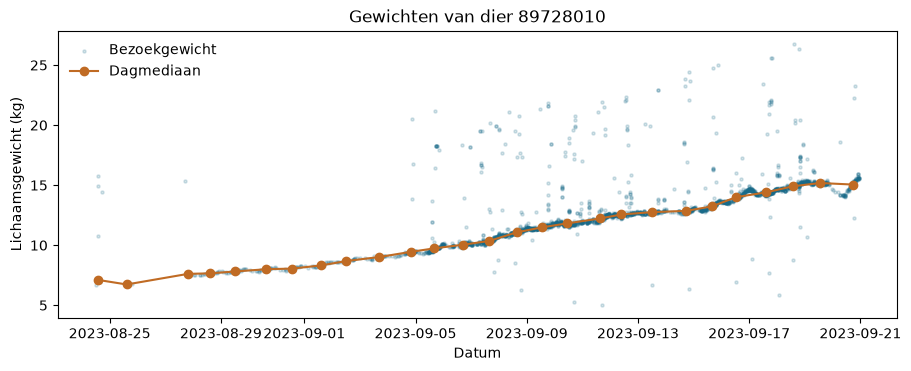

In [6]:
dag = daggewichten(gewichten)
voorbeeld_dier = populatie.iloc[0]["dier_id"]
voorbeeld_dagen = dag[dag["dier_id"] == voorbeeld_dier]
display(voorbeeld_dagen.head(7))
fig, ax = plt.subplots(figsize=(9, 3.6), layout="constrained")
ruw = gewichten[gewichten["dier_id"] == voorbeeld_dier]
ax.scatter(ruw["tijd"], ruw["waarde"], s=5, alpha=.18, color="#176a89", label="Bezoekgewicht")
ax.plot(voorbeeld_dagen["tijd"], voorbeeld_dagen["gewicht_kg"], "o-", color="#c06b24", label="Dagmediaan")
ax.set(title=f"Gewichten van dier {voorbeeld_dier}", xlabel="Datum", ylabel="Lichaamsgewicht (kg)")
ax.legend(frameon=False)
plt.show()

<div style="text-align:justify;box-sizing:border-box;max-width:100%;overflow-wrap:anywhere;">

*Figuur 1. Bezoekgewichten en dagmedianen van één dier. De verbindingslijn maakt het verloop zichtbaar, maar stelt geen voortdurend gemeten gewicht voor.*

</div>

<div style="background-color:#e3f2fd;color:#0d47a1;border-left:5px solid #1976d2;padding:14px;margin:12px 0;border-radius:4px;text-align:justify;box-sizing:border-box;max-width:100%;overflow-wrap:anywhere;white-space:normal;"><strong>Facultatieve verkenning 1</strong><br>Hoe groot zijn de gewichtsverschillen tussen dieren binnen één hok? Bereken voor een gekozen dag de mediaan en het eerste en derde kwartiel van de dierdagmedianen. Probeer daarna een ander hok. Gebruik nieuwe variabelen met de naam <code>verkenning_...</code>, zodat je de basisberekening behoudt.</div>

In [7]:
# FACULTATIEF: kies een hok en dag.
# Selecteer rijen uit dag en gebruik .quantile([0.25, 0.5, 0.75]) op gewicht_kg.
# Verklaar of je spreiding tussen dieren of tussen bezoeken van hetzelfde dier onderzoekt.

In [8]:
verkenning_hok = "1"
verkenning_dag = pd.Timestamp("2023-09-10")
verkenning_selectie = dag[(dag["hok"] == verkenning_hok) & (dag["dag"] == verkenning_dag)]
display(verkenning_selectie["gewicht_kg"].quantile([0.25, 0.5, 0.75]).rename("gewicht_kg"))
print("Deze spreiding betreft verschillen tussen dieren, elk vertegenwoordigd door één dagmediaan.")

0.25    11.9175
0.50    13.1900
0.75    14.4300
Name: gewicht_kg, dtype: float64

Deze spreiding betreft verschillen tussen dieren, elk vertegenwoordigd door één dagmediaan.


## 5. Eén geïntegreerde berekening volgen

<div style="text-align:justify;box-sizing:border-box;max-width:100%;overflow-wrap:anywhere;">

**Uitvoeren:** in Codespaces (Notebook 07)

Voor hetzelfde dier en hetzelfde interval combineer je nu beide bronnen. De geschatte gewichtstoename is eindgewicht min begingewicht. De voederopname is de som van alle geregistreerde bezoekopnames binnen dat interval, omgerekend van gram naar kilogram.

Een bezoek hoort bij de periode waarin het begint: de begingrens telt mee, de eindgrens niet. Een bezoek over een grens wordt volledig aan zijn startperiode toegewezen. Dat is een praktische benadering voor bezoekgegevens, geen exacte verdeling van voer over seconden. Het aantal bezoeken dat over de intervalgrens loopt wordt apart geteld.

Voor iedere kalenderdag moet minstens één geldig voederrecord aanwezig zijn. Dat kan ook een geregistreerd nulbezoek zijn. Deze controle ontdekt ontbrekende dagen, maar bewijst niet dat alle bezoeken binnen een aanwezige dag zijn geregistreerd.

</div>

| Berekening | Formule | Eenheid |
|---|---|---|
| Gewichtstoename | Eindgewicht − begingewicht | kg |
| Gemiddelde dagelijkse groei | Gewichtstoename × 1000 / dagen | g per dier per dag |
| Gemiddelde dagelijkse voederopname | Voederopname in kg × 1000 / dagen | g per dier per dag |
| Voederconversie | Voederopname in kg / gewichtstoename in kg | kg voeder per kg groei |

In [9]:
dierintervallen = bereken_intervallen(dag, voeder, populatie, grenzen, max_uren=max_uren)
voorbeeld = dierintervallen[dierintervallen["bruikbaar"]].iloc[0]
toename = voorbeeld["eind_kg"] - voorbeeld["begin_kg"]
opname = voorbeeld["voeder_kg"]
print("Dier:", voorbeeld["dier_id"], "| Hok:", voorbeeld["hok"])
print("Periode:", voorbeeld["vanaf"], "tot", voorbeeld["tot"], "(exclusief)")
print(f"Gewicht: {voorbeeld['begin_kg']:.3f} naar {voorbeeld['eind_kg']:.3f} kg")
print(f"Groei: {toename:.3f} kg / {voorbeeld['dagen']} dagen = {1000 * toename / voorbeeld['dagen']:.1f} g/dag")
print(f"Voeder: {opname:.3f} kg / {voorbeeld['dagen']} dagen = {1000 * opname / voorbeeld['dagen']:.1f} g/dag")
print(f"Voederconversie: {opname:.3f} / {toename:.3f} = {opname / toename:.3f} kg/kg")
assert np.isclose(opname / toename, voorbeeld["voederconversie"])

Dier: 89728010 | Hok: 3
Periode: 2023-08-25 00:00:00 tot 2023-09-01 00:00:00 (exclusief)
Gewicht: 6.955 naar 8.164 kg
Groei: 1.209 kg / 7 dagen = 172.7 g/dag
Voeder: 1.501 kg / 7 dagen = 214.4 g/dag
Voederconversie: 1.501 / 1.209 = 1.242 kg/kg


<div style="text-align:justify;box-sizing:border-box;max-width:100%;overflow-wrap:anywhere;">

**Vraag 2.** Wat betekent de berekende voederconversie van dit dier in gewone woorden?

</div>

<div style="text-align:justify;box-sizing:border-box;max-width:100%;overflow-wrap:anywhere;">

**Jouw antwoord (Vraag 2):**

*Voeg hier je antwoord in. Tip: gebruik de getallen uit jouw uitvoer en benoem zowel het voeder als de groei.*

</div>

<div style="text-align:justify;box-sizing:border-box;max-width:100%;overflow-wrap:anywhere;">

**Antwoord 2**

Voor dier 89728010 in hok 3, van 25 augustus tot 1 september, bedraagt de geregistreerde opname 1,501 kg en de geschatte groei ongeveer 1,209 kg. Dat geeft ongeveer 1,242 kg voeder per kg geschatte gewichtstoename. Het is een verhouding over dit interval, geen dagelijkse hoeveelheid voer.

</div>

## 6. Controleren welke dierintervallen bruikbaar zijn

<div style="text-align:justify;box-sizing:border-box;max-width:100%;overflow-wrap:anywhere;">

**Uitvoeren:** in Codespaces (Notebook 07)

Voordat je hokken vergelijkt, bekijk je de uitsluitingen. Een dier kan in het ene interval bruikbaar zijn en in een ander interval ontbreken. De oorspronkelijke groep blijft zichtbaar in `populatie`, terwijl `bruikbaar` aangeeft of een dier aan alle voorwaarden voor dat interval voldoet.

</div>

In [10]:
display(dierintervallen.groupby(["interval", "reden"]).size().rename("dierintervallen").reset_index())
dekking = dierintervallen.groupby("interval")["bruikbaar"].agg(["sum", "count"])
dekking.columns = ["bruikbaar", "populatie"]
display(dekking)
print("Bezoeken over de gekozen eindgrenzen:", int(dierintervallen["grensbezoeken"].sum()))

,interval,reden,dierintervallen
0,1,begin_gewichtsgat_te_groot,11
1,1,begin_gewichtsgat_te_groot;voederdagen_ontbreken,1
2,1,bruikbaar,77
3,1,eind_gewicht_niet_omsloten;voederdagen_ontbreken,1
4,1,geen_positieve_groei,10
5,1,voederdagen_ontbreken,1
6,2,begin_gewicht_niet_omsloten;eind_gewicht_niet_...,1
7,2,bruikbaar,98
8,2,eind_gewicht_niet_omsloten;voederdagen_ontbreken,1
9,2,eind_gewichtsgat_te_groot,1


,bruikbaar,populatie
interval,,
1,77,101
2,98,101
3,98,101
4,98,101


Bezoeken over de gekozen eindgrenzen: 0


<div style="text-align:justify;box-sizing:border-box;max-width:100%;overflow-wrap:anywhere;">

**Vraag 3.** Welk interval heeft de laagste dekking, en waarom vraagt dat extra voorzichtigheid bij een vergelijking?

</div>

<div style="text-align:justify;box-sizing:border-box;max-width:100%;overflow-wrap:anywhere;">

**Jouw antwoord (Vraag 3):**

*Voeg hier je antwoord in. Tip: gebruik het aantal bruikbare dieren en minstens één uitsluitingsreden uit de tabel.*

</div>

<div style="text-align:justify;box-sizing:border-box;max-width:100%;overflow-wrap:anywhere;">

**Antwoord 3**

Het eerste interval heeft 77 bruikbare dieren op 101. In elk later interval zijn het er 98. In het eerste interval ontbreken onder meer voldoende nabije beginwegingen en zijn er tien dieren zonder positieve geschatte groei. Het resultaat beschrijft dus een geselecteerde groep. Een gunstige verhouding mag niet worden voorgesteld als de prestatie van alle 101 biggen.

</div>

## 7. Van dieren naar hokken rekenen

<div style="text-align:justify;box-sizing:border-box;max-width:100%;overflow-wrap:anywhere;">

**Uitvoeren:** in Codespaces (Notebook 07)

Voor een hok gebruik je dezelfde bruikbare dieren voor de voederopname én de gewichtstoename. Je telt hun voeder en groei afzonderlijk op. De voederconversie van het hok is vervolgens totaal voeder gedeeld door totale groei. Je neemt niet het gewone gemiddelde van de individuele verhoudingen, want dieren met weinig groei zouden daarin even zwaar meetellen als dieren met veel groei.

De gemiddelde groei en opname per dier per dag worden berekend door de totalen te delen door het aantal meegenomen dieren en het aantal dagen. Het aantal meegenomen dieren staat bij ieder hokinterval. Een hok met onvolledige dekking beschrijft alleen die beschikbare groep.

</div>

In [11]:
hokresultaten = vat_hokken_samen(dierintervallen)
kolommen = ["hok", "interval", "dagen", "dieren_bruikbaar", "dieren_populatie",
            "groei_g_dier_dag", "voeder_g_dier_dag", "voederconversie"]
display(hokresultaten[kolommen].round(3))
hokvoorbeeld = hokresultaten[(hokresultaten["hok"] == "1") & (hokresultaten["interval"] == 1)].iloc[0]
print(f"Hok 1, interval 1: {hokvoorbeeld['voeder_kg']:.3f} kg voer / {hokvoorbeeld['groei_kg']:.3f} kg groei")
print(f"Voederconversie: {hokvoorbeeld['voederconversie']:.3f} kg/kg")

,hok,interval,dagen,dieren_bruikbaar,dieren_populatie,groei_g_dier_dag,voeder_g_dier_dag,voederconversie
0,1,1,7,10,11,209.418,221.300,1.057
1,1,2,7,11,11,445.819,459.727,1.031
2,1,3,7,11,11,489.260,653.182,1.335
3,1,4,5,11,11,572.242,724.927,1.267
4,10,1,7,6,10,172.906,208.333,1.205
5,10,2,7,10,10,396.628,424.771,1.071
6,10,3,7,10,10,443.459,600.200,1.353
7,10,4,5,10,10,417.090,620.560,1.488
8,2,1,7,8,10,122.749,164.679,1.342
9,2,2,7,10,10,371.283,405.671,1.093


Hok 1, interval 1: 15.491 kg voer / 14.659 kg groei
Voederconversie: 1.057 kg/kg


<div style="text-align:justify;box-sizing:border-box;max-width:100%;overflow-wrap:anywhere;">

**Doe-opdracht.** Kies een ander hok dan hok 1 en een interval uit de tabel. Selecteer de rij uit `hokresultaten` en controleer zelf of `voeder_kg / groei_kg` dezelfde voederconversie geeft. Bewaar je keuzes als `gekozen_hok` en `gekozen_interval`, en de geselecteerde rij als `eigen_resultaat`.

</div>

In [12]:
# SCHRIJF HIER JE CODE:
# 1. Kies gekozen_hok als tekst, bijvoorbeeld "9".
# 2. Kies gekozen_interval als geheel getal van 1 tot 4.
# 3. Selecteer de rij met beide voorwaarden en .iloc[0].
# 4. Bereken eigen_conversie = voeder_kg / groei_kg voor deze rij.

In [13]:
gekozen_hok = "9"
gekozen_interval = 4
eigen_resultaat = hokresultaten[(hokresultaten["hok"] == gekozen_hok) &
                              (hokresultaten["interval"] == gekozen_interval)].iloc[0]
eigen_conversie = eigen_resultaat["voeder_kg"] / eigen_resultaat["groei_kg"]

In [14]:
assert gekozen_hok in set(populatie["hok"]) and gekozen_hok != "1"
assert gekozen_interval in range(1, len(grenzen))
assert eigen_resultaat["hok"] == gekozen_hok and eigen_resultaat["interval"] == gekozen_interval
assert np.isclose(eigen_conversie, eigen_resultaat["voederconversie"])
print(f"Hok {gekozen_hok}, interval {gekozen_interval}: {eigen_conversie:.3f} kg voeder per kg groei")
print("Dieren meegenomen:", int(eigen_resultaat["dieren_bruikbaar"]), "van", int(eigen_resultaat["dieren_populatie"]))

Hok 9, interval 4: 1.165 kg voeder per kg groei
Dieren meegenomen: 10 van 10


## 8. De ontwikkeling per hok visualiseren

<div style="text-align:justify;box-sizing:border-box;max-width:100%;overflow-wrap:anywhere;">

**Uitvoeren:** in Codespaces (Notebook 07)

Een grafiek laat zien of verschillen al vroeg aanwezig zijn en of de rangorde tussen hokken verandert. De panelen gebruiken dezelfde assen, zodat een verschil in schaal niet voor een biologisch verschil wordt aangezien.

Begin met het gemiddelde lichaamsgewicht per hok. Dit is per dag het gemiddelde van de beschikbare dierdagmedianen. Het aantal aanwezige dieren kan veranderen. Een verschuiving in het hokgemiddelde kan daardoor zowel door groei als door een andere samenstelling van de beschikbare groep ontstaan.

</div>

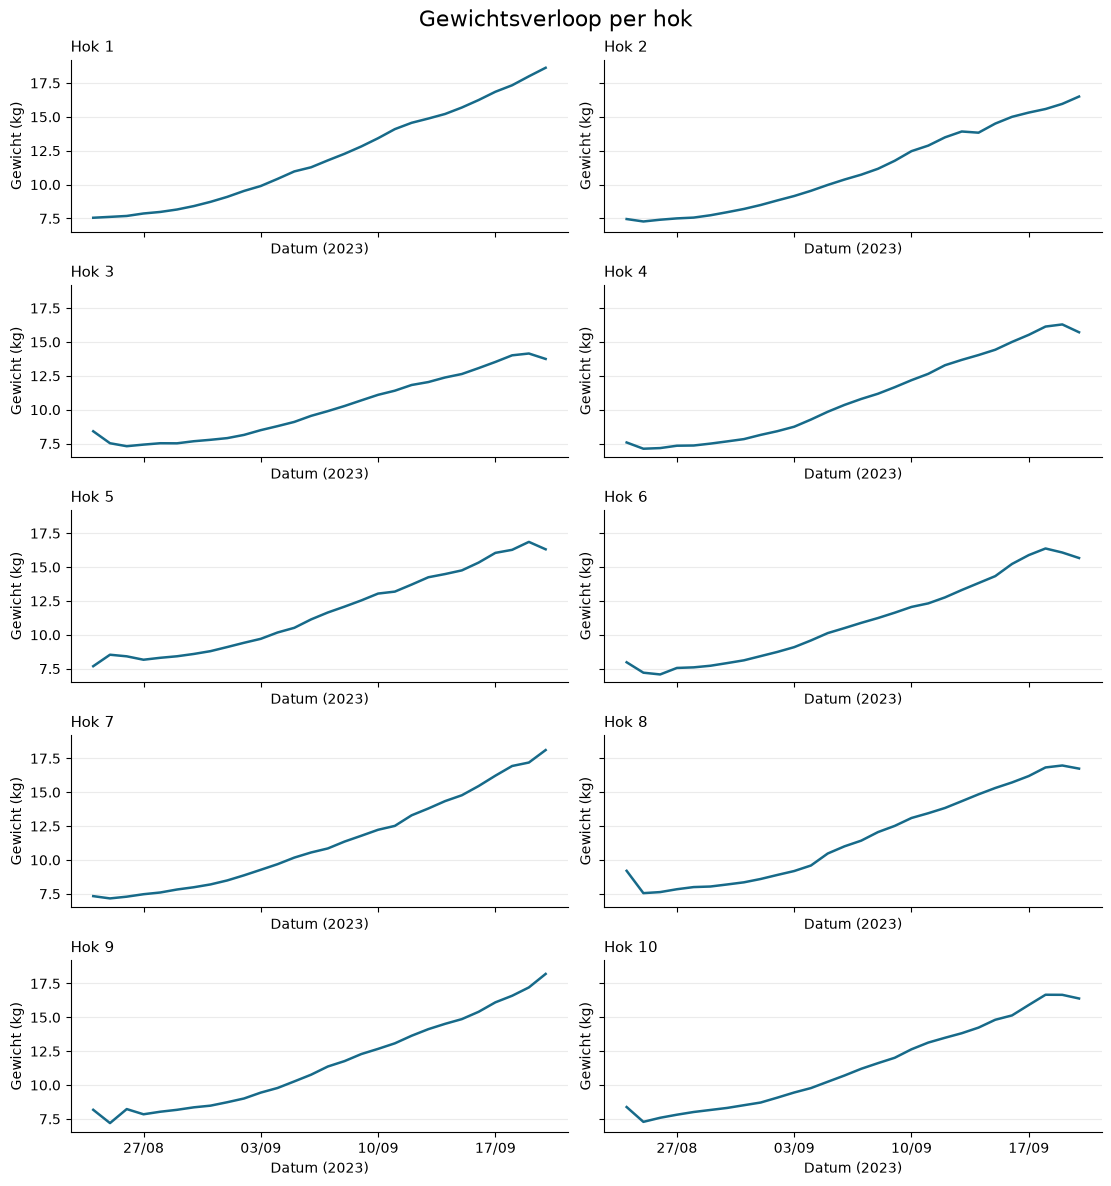

In [15]:
fig_gewicht = gewichtsfiguur(dag)
plt.show()

<div style="text-align:justify;box-sizing:border-box;max-width:100%;overflow-wrap:anywhere;">

*Figuur 2. Gemiddelde van de beschikbare dierdagmedianen per hok en kalenderdag. De lijn beschrijft een wisselend aantal waargenomen dieren en is geen individuele groeicurve.*

Vergelijk daarna de gemiddelde dagelijkse groei en voederopname binnen de vaste intervallen. Beide lijnen hebben dezelfde eenheid, gram per dier per dag, en zijn op dezelfde bruikbare dieren gebaseerd. Een punt vat het hele bijbehorende interval samen. Het is geen afzonderlijke dagmeting.

</div>

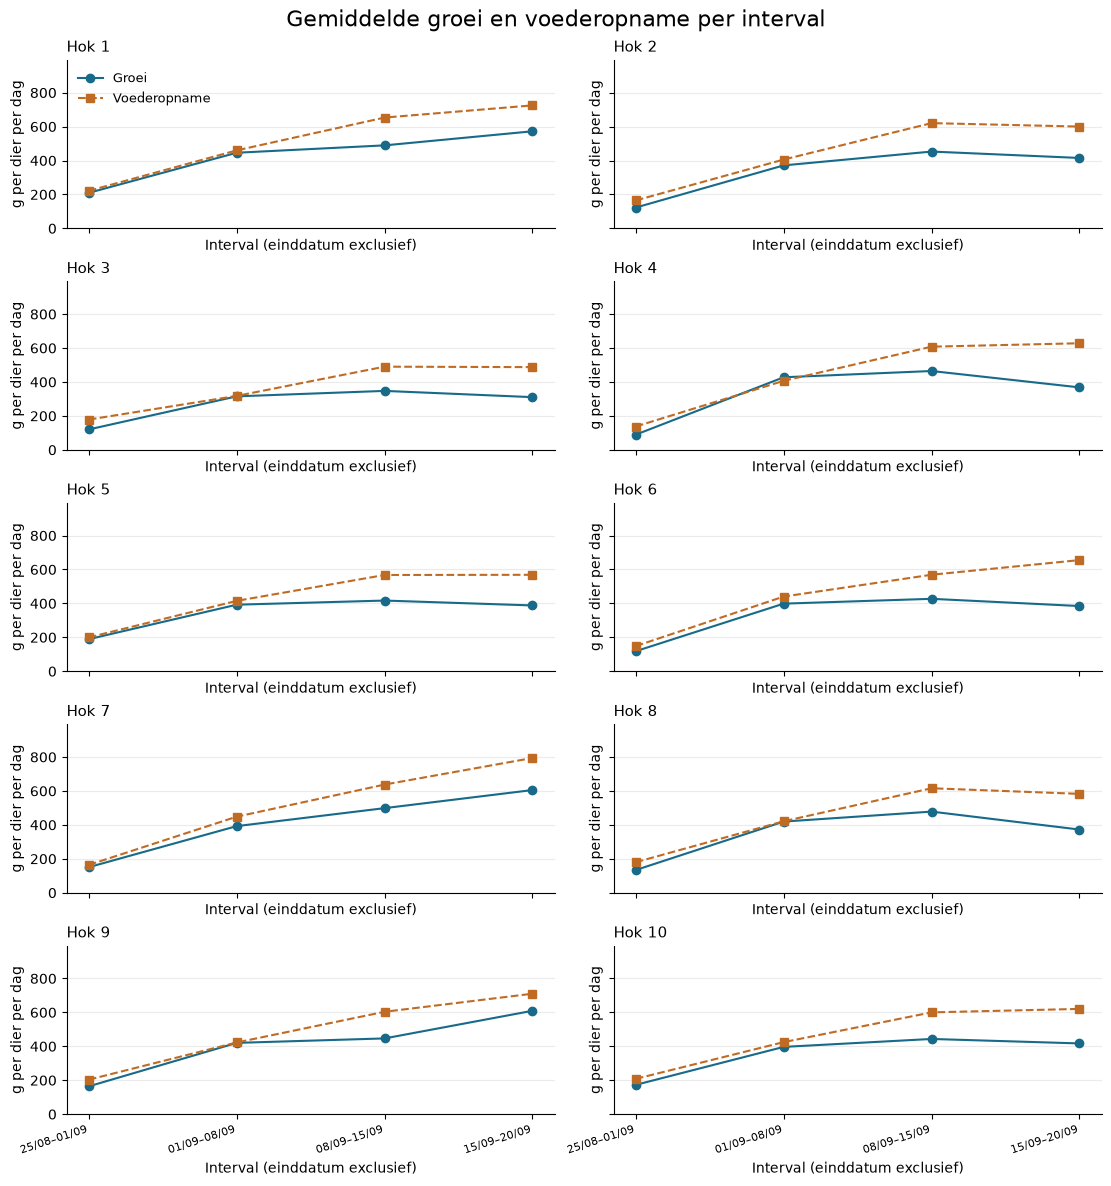

In [16]:
fig_groei_voeder = intervalfiguur(hokresultaten, "groei_voeder")
plt.show()

<div style="text-align:justify;box-sizing:border-box;max-width:100%;overflow-wrap:anywhere;">

*Figuur 3. Gemiddelde groei en voederopname voor dezelfde bruikbare dieren per hokinterval. De laatste periode duurt vijf dagen, de andere perioden zeven dagen.*

De volgende figuur toont de verhouding tussen voederopname en groei. Bij ieder punt staat hoeveel dieren bijdragen aan de uitkomst. Een lagere verhouding betekent minder geregistreerd voeder per kilogram geschatte groei binnen dat interval. Beoordeel daarnaast de groeisnelheid en gegevensdekking.

</div>

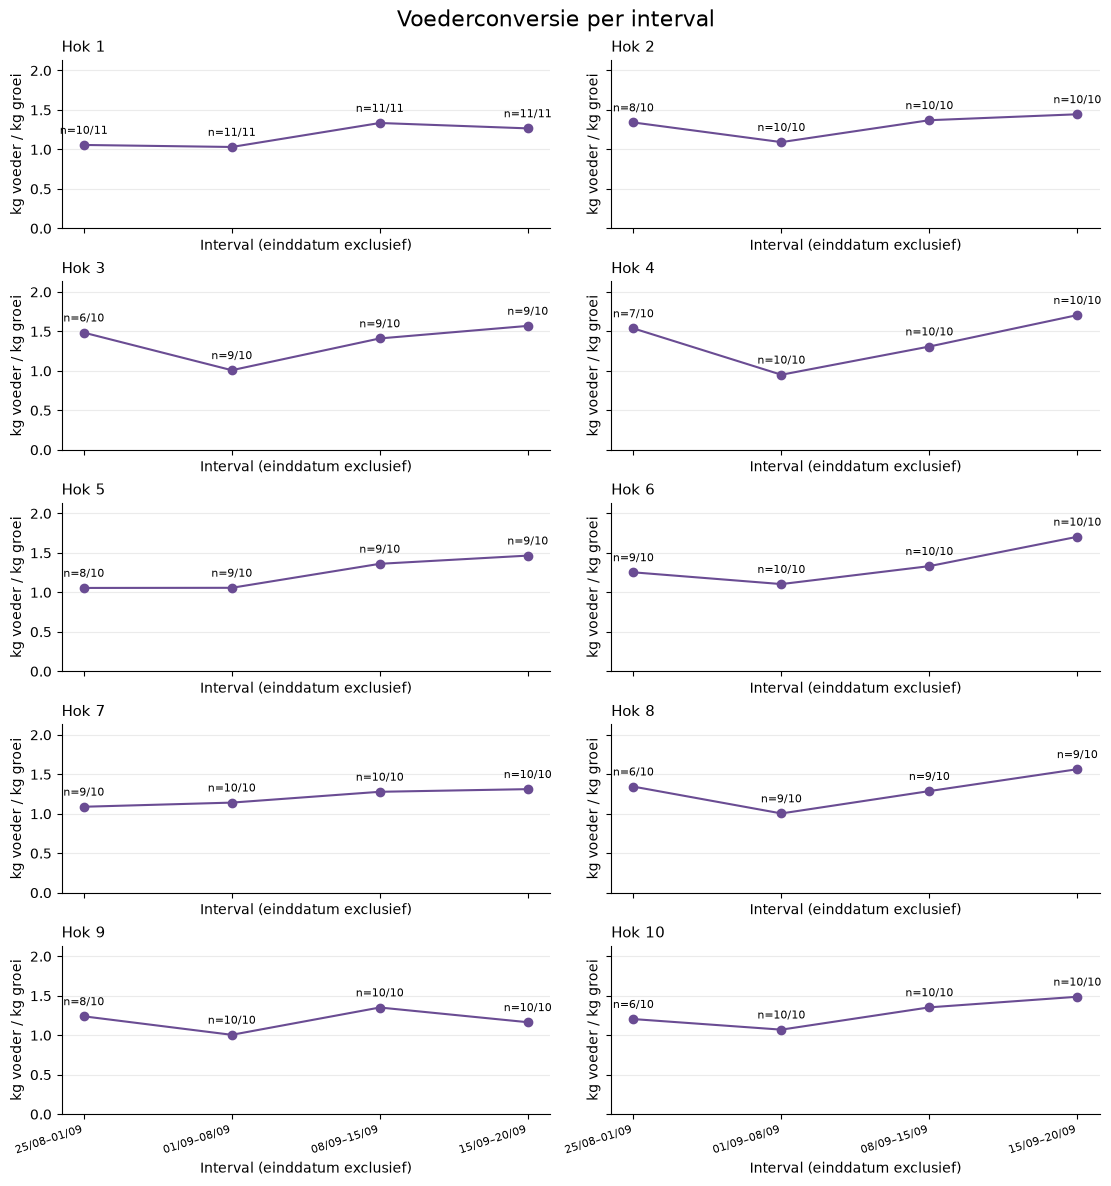

In [17]:
fig_conversie = intervalfiguur(hokresultaten, "conversie")
plt.show()

<div style="text-align:justify;box-sizing:border-box;max-width:100%;overflow-wrap:anywhere;">

*Figuur 4. Voederconversie uit de som van opname en groei van de bruikbare dieren. Het label n geeft bruikbare dieren tegenover de oorspronkelijke gekoppelde hokgroep.*

</div>

<div style="background-color:#e3f2fd;color:#0d47a1;border-left:5px solid #1976d2;padding:14px;margin:12px 0;border-radius:4px;text-align:justify;box-sizing:border-box;max-width:100%;overflow-wrap:anywhere;white-space:normal;"><strong>Facultatieve verkenning 2</strong><br>Maak voor één interval een spreidingsdiagram met gemiddelde groei op de horizontale as en voederconversie op de verticale as. Geef ieder punt een hoknummer. Welk hok combineert in die periode relatief snelle groei met een relatief lage conversie? Probeer daarna een ander interval en kijk of je conclusie verandert.</div>

In [18]:
# FACULTATIEF:
# Selecteer één interval uit hokresultaten in verkenning_selectie.
# Gebruik ax.scatter(groei_g_dier_dag, voederconversie).
# Voeg hoknummers toe met ax.annotate en benoem de eenheden.

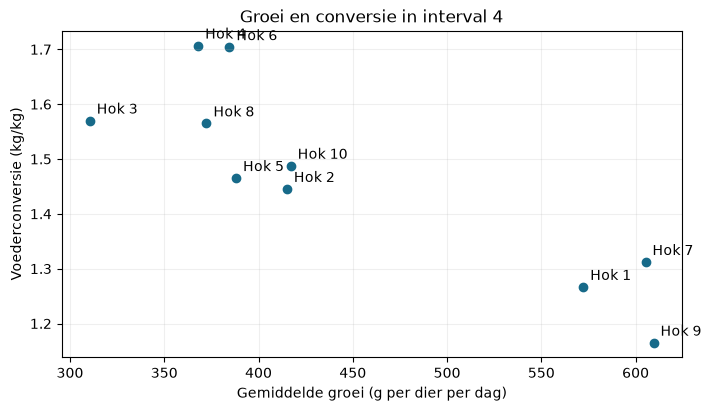

In [19]:
verkenning_interval = 4
verkenning_selectie = hokresultaten[hokresultaten["interval"] == verkenning_interval]
fig, ax = plt.subplots(figsize=(7, 4), layout="constrained")
ax.scatter(verkenning_selectie["groei_g_dier_dag"], verkenning_selectie["voederconversie"], color="#176a89")
for rij in verkenning_selectie.itertuples():
    ax.annotate(f"Hok {rij.hok}", (rij.groei_g_dier_dag, rij.voederconversie), xytext=(5, 5), textcoords="offset points")
ax.set(xlabel="Gemiddelde groei (g per dier per dag)", ylabel="Voederconversie (kg/kg)",
       title=f"Groei en conversie in interval {verkenning_interval}")
ax.grid(alpha=.2)
plt.show()

## 9. Verschillen interpreteren en een vervolgvraag formuleren

<div style="text-align:justify;box-sizing:border-box;max-width:100%;overflow-wrap:anywhere;">

Op dit bedrijf zijn vier voederstrategieën toegepast. De biggen kregen eerst een voeder met een hoger of lager eiwitgehalte. Na tien of achttien dagen werd overgeschakeld naar hetzelfde vervolgvoeder. De tabel beschrijft de beschikbare strategieën. Je onderzoekt met de hokpatronen welke verklaringen aannemelijk zijn.

</div>

| Strategie | Eiwitgehalte eerste voeder | Overschakeling | Eiwitgehalte vervolgvoeder |
|---|---|---|---|
| Hoger eiwit, kort | 188 g ruw eiwit/kg | Na 10 dagen | 179 g/kg |
| Hoger eiwit, lang | 188 g ruw eiwit/kg | Na 18 dagen | 179 g/kg |
| Lager eiwit, kort | 162 g ruw eiwit/kg | Na 10 dagen | 179 g/kg |
| Lager eiwit, lang | 162 g ruw eiwit/kg | Na 18 dagen | 179 g/kg |

<div style="text-align:justify;box-sizing:border-box;max-width:100%;overflow-wrap:anywhere;">

Een snellere groei bewijst niet op zichzelf welke strategie een hok kreeg. Beginmassa, voederopname, uitval, registratiekwaliteit en verschillen tussen dieren kunnen ook bijdragen. De grafieken zijn een basis voor een hypothese. Ze geven nog geen zekere behandelingstoewijzing of oorzakelijk bewijs.

Een bedrijfskeuze vraagt bovendien meer dan de laagste voederconversie. Ook groeisnelheid, gezondheid en voederkosten kunnen belangrijk zijn. Die laatste twee zijn hier niet berekend. In notebook 08 beoordeel je je voorlopige interpretatie opnieuw nadat de aanvullende meetdagen door de volledige gegevensketen zijn verwerkt.

</div>

<div style="text-align:justify;box-sizing:border-box;max-width:100%;overflow-wrap:anywhere;">

**Vraag 4.** Vergelijk hok 1 en hok 9 in het eerste en laatste interval. Blijft de rangorde voor voederconversie gelijk?

</div>

<div style="text-align:justify;box-sizing:border-box;max-width:100%;overflow-wrap:anywhere;">

**Jouw antwoord (Vraag 4):**

*Voeg hier je antwoord in. Tip: noteer vier waarden en controleer de aantallen dieren.*

</div>

<div style="text-align:justify;box-sizing:border-box;max-width:100%;overflow-wrap:anywhere;">

**Antwoord 4**

In het eerste interval is de conversie ongeveer 1,057 voor hok 1 en 1,240 voor hok 9. In het laatste interval is dat ongeveer 1,267 en 1,165. De rangorde verandert dus. De eerste vergelijking gebruikt 10 van 11 dieren in hok 1 en 8 van 10 in hok 9. De laatste gebruikt respectievelijk 11 en 10 dieren. Een verschil in dekking beperkt de vergelijking.

</div>

<div style="text-align:justify;box-sizing:border-box;max-width:100%;overflow-wrap:anywhere;">

**Vraag 5.** Welk hok wil je nader onderzoeken, en welke extra informatie heb je nodig voordat je een voederstrategie aanbeveelt?

</div>

<div style="text-align:justify;box-sizing:border-box;max-width:100%;overflow-wrap:anywhere;">

**Jouw antwoord (Vraag 5):**

*Voeg hier je antwoord in. Tip: gebruik minstens één getal uit een figuur of tabel en benoem een beperking.*

</div>

<div style="text-align:justify;box-sizing:border-box;max-width:100%;overflow-wrap:anywhere;">

**Antwoord 5**

Hok 9 is interessant: in het laatste interval groeit de beschikbare groep gemiddeld ongeveer 609,5 g per dier per dag bij een conversie van ongeveer 1,165 kg/kg. Dat is een aanleiding om het patroon met de latere dagen te controleren. Voor een voederadvies wil ik ook weten of die prestatie aanhoudt, welke dieren ontbreken en hoe gezondheid en voederkosten verschillen. Deze grafiek alleen bewijst de gebruikte strategie niet.

</div>

## 10. De beginsituatie voor notebook 08 bewaren

<div style="text-align:justify;box-sizing:border-box;max-width:100%;overflow-wrap:anywhere;">

**Uitvoeren:** in Codespaces (Notebook 07)

Je bewaart de berekende resultaten samen met de populatie, tijdsgrenzen en kwaliteitsregels. Zo kun je in notebook 08 een nieuw overzicht met precies deze beginsituatie vergelijken. De functie schrijft bij de eerste uitvoering een map `beginsituatie_07`. Een herhaling met dezelfde inhoud is toegestaan. Afwijkende resultaten overschrijven de eerdere beginsituatie niet.

De figuren en het controlebestand worden automatisch uit je uitvoering gemaakt. Je hoeft geen afzonderlijk verslag te schrijven. Vul wel je eigen interpretaties in de antwoordcellen aan.

</div>

In [20]:
inlevermap = hoofdmap / "gegevens/inlevering"
basisbeschrijving = bewaar_basis(inlevermap / "beginsituatie_07", populatie, dag,
                                dierintervallen, hokresultaten, bronmanifest, regels)
for naam, figuur in [("07_gewichtsverloop.png", fig_gewicht),
                    ("07_groei_en_voederopname.png", fig_groei_voeder),
                    ("07_voederconversie.png", fig_conversie)]:
    figuur.savefig(inlevermap / naam, dpi=140, bbox_inches="tight")
controle = {
    "deelnemerscode": deelnemer, "branch": branch, "rol": rol,
    "getest_op_utc": datetime.now(timezone.utc).isoformat(), "methode": METHODE,
    "populatie": len(populatie), "hokken": hokvolgorde(populatie["hok"]),
    "bruikbare_dieren_per_interval": {str(k): int(v) for k, v in dierintervallen.groupby("interval")["bruikbaar"].sum().items()},
    "gekozen_hok": gekozen_hok, "gekozen_interval": gekozen_interval,
    "eigen_voederconversie": float(eigen_conversie), "basis": basisbeschrijving,
}
(inlevermap / "07_analysecontrole.json").write_text(json.dumps(controle, ensure_ascii=False, indent=2) + "\n", encoding="utf-8")
print("Beginsituatie, drie figuren en 07_analysecontrole.json bewaard.")
print("Herhaling bewaren:", bewaar_basis(inlevermap / "beginsituatie_07", populatie, dag,
                                       dierintervallen, hokresultaten, bronmanifest, regels) == basisbeschrijving)

Beginsituatie, drie figuren en 07_analysecontrole.json bewaard.
Herhaling bewaren: True


<div style="background-color:#e8f5e9;color:#1b5e20;border-left:5px solid #2e7d32;padding:14px;margin:12px 0;border-radius:4px;text-align:justify;box-sizing:border-box;max-width:100%;overflow-wrap:anywhere;white-space:normal;"><strong>Controle</strong><br>De map <code>beginsituatie_07</code> bevat de populatie, daggewichten, dierintervallen, hokresultaten en een beschrijving met controlesommen. Bij een gewijzigde methode maak je later een afzonderlijke vergelijking. Verwijder de oorspronkelijke beginsituatie niet om een verschilmelding te omzeilen.</div>

<div style="background-color:#fff8e1;color:#6d4c00;border-left:5px solid #f9a825;padding:14px;margin:12px 0;border-radius:4px;text-align:justify;box-sizing:border-box;max-width:100%;overflow-wrap:anywhere;white-space:normal;"><strong>Stop je Codespace na het practicum</strong><br>Bewaar je werk, commit en push voordat je de Codespace stopt. Je Droplet heeft afzonderlijke kosten en blijft beschikbaar volgens de afspraak met de docent.</div>

<div style="text-align:justify;box-sizing:border-box;max-width:100%;overflow-wrap:anywhere;">

**Uitvoeren:** in Codespaces (Source Control) en op de GitHub-website

1. Vul je antwoorden aan en kies **File → Save All**.
2. Selecteer notebook 07, `07_analysecontrole.json`, de drie `07_...png`-figuren en alle bestanden uit `gegevens/inlevering/beginsituatie_07/` in **Source Control**.
3. Commit bijvoorbeeld met **Groei en voederconversie per hok onderzocht**. Kies **Push** en controleer de bestanden op jouw GitHub-branch.
4. Je analysedatabase blijft onder `gegevens/werk/` en wordt niet gecommit. Hervat later dezelfde Codespace. Bij een nieuwe Codespace moet je het analysebestand herstellen of opnieuw via notebook 06 ophalen.
5. Stop de Codespace via [github.com/codespaces](https://github.com/codespaces).

Bij de volgende oefening voeg je latere gegevens toe. Je onderzoekt dan zowel dezelfde vaste basisperiode als de uitgebreidere periode. Zo onderscheid je een andere berekening van werkelijk nieuwe informatie.

</div>

Hulp bij veelvoorkomende problemen

| Probleem | Controle en herstel |
|---|---|
| analyse_06.db of controlebestand ontbreekt | Hervat notebook 06 in dezelfde Codespace en voer de inlevercel uit. |
| Inhoud wijkt af van 06 | Controleer of je het juiste analysebestand gebruikt en of de API-import intussen is bijgewerkt. |
| Dubbele identificatie of verkeerde eenheid | Herstel de import. Verwijder niet willekeurig records om verder te kunnen. |
| Ontbrekend grensgewicht | Bekijk de dagmedianen rond de grens. De methode extrapoleert niet en overbrugt geen gaten groter dan 48 uur. |
| Voederdagen ontbreken | Geen records is niet hetzelfde als nul opname. Controleer de geregistreerde periode en ontvangst. |
| Geen positieve groei | Er wordt geen voederconversie berekend. Onderzoek het dier en de meetkwaliteit. |
| Onverwacht lage of hoge conversie | Controleer opname, begin- en eindgewicht, interval en dekking. Behandel de verhouding niet automatisch als een biologische verklaring. |
| Beginsituatie verschilt | Behoud de eerder bewaarde map. Controleer gewijzigde instellingen en bespreek hoe je een aparte vergelijking bewaart. |
| NameError na hervatten | Voer de codecellen opnieuw in volgorde uit. Bestanden blijven behouden, variabelen in het geheugen niet. |

Technische bronnen en methode

<div style="text-align:justify;box-sizing:border-box;max-width:100%;overflow-wrap:anywhere;">

- [Gegevenswoordenboek](../../gegevens/gegevenswoordenboek.md)
- [Rekenmethode en referentiecontrole](../../documentatie/rekenmethode_07.md)
- [Ontario: voederopname, groei en voederconversie bij varkens](https://www.ontario.ca/page/providing-feed-and-water-pigs)
- [pandas: groeperen en aggregeren](https://pandas.pydata.org/docs/user_guide/groupby.html)
- [Matplotlib: figuren met meerdere panelen](https://matplotlib.org/stable/gallery/subplots_axes_and_figures/subplots_demo.html)

De brongegevens komen uit een voederproef met 101 biggen. De lesberekening gebruikt een afzonderlijke, uitgelegde methode voor verkennende bedrijfsanalyse. De oorspronkelijke data bevatten ook kwaliteitsinformatie uit eerdere verwerking. Daarom is dit geen voorspelling zonder kennis van latere meetdagen.

</div>